# Milestone 11 — Photometric and Geometric Analysis

**Target:** MaNGA 8138-12704 · DAPTYPE HYB10-MILESHC-MASTARSSP

## Objectives
1. Locate target in the MaNGA DRPall catalogue.
2. Extract documented NSA elliptical-Petrosian geometry: photometric PA, axis ratio, ellipticity and half-light radius.
3. Validate the effective radius used by the DAP radial coordinates.
4. Compare photometric and kinematic PA only after confirming the catalogue PA convention.
5. Export a geometry summary and diagnostic figure.

**Scientific safeguard:** Never infer photometric PA from the velocity map. If DRPall is unavailable or the PA convention is not verified, the notebook explicitly leaves the comparison pending. This notebook is a local execution template; it has not been run against your computer's files.


In [15]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits

# ============================================================
# 1. PROJECT CONFIGURATION
# ============================================================

PROJECT_NAME = "manga-stellar-kinematics"

MAPS_FILENAME = (
    "manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits.gz"
)

DRPALL_FILENAMES = [
    "drpall-v3_1_1.fits",
    "drpall-v3_1_1.fits.gz",
    "drpall-v3_1_1.fits.fz"
]

PLATE = 8138
IFU = 12704

KIN_PA_DEG = 167.300313

# ============================================================
# 2. AUTOMATIC PROJECT ROOT DETECTION
# ============================================================

CWD = Path.cwd().resolve()

def find_project_root(start):
    """
    Search for the project root using the MAPS file.
    Checks current directory and its parent directories.
    """

    for folder in [start, *start.parents]:

        possible_maps = (
            folder / "data" / "raw" / MAPS_FILENAME
        )

        if possible_maps.is_file():
            return folder

    # Search within current directory and subdirectories
    for maps_file in start.rglob(MAPS_FILENAME):

        if maps_file.is_file():
            return maps_file.parent.parent.parent

    raise FileNotFoundError(
        "\nMAPS file could not be located.\n"
        f"Current directory: {CWD}\n"
        f"Expected filename: {MAPS_FILENAME}\n"
        "Check whether the FITS file has been downloaded."
    )


ROOT = find_project_root(CWD)

print("Project Root:", ROOT)

# ============================================================
# 3. INPUT FILE PATHS
# ============================================================

RAW = ROOT / "data" / "raw"

MAPS = RAW / MAPS_FILENAME

DRPALL_CANDIDATES = [
    RAW / filename
    for filename in DRPALL_FILENAMES
]

DRPALL = next(
    (path for path in DRPALL_CANDIDATES if path.is_file()),
    None
)

# ============================================================
# 4. OUTPUT DIRECTORIES
# ============================================================

OUT = ROOT / "outputs"

FIG = OUT / "figures"
REP = OUT / "reports"

for folder in [OUT, FIG, REP]:
    folder.mkdir(parents=True, exist_ok=True)

# ============================================================
# 5. FILE VALIDATION
# ============================================================

if not MAPS.is_file():
    raise FileNotFoundError(
        f"MAPS file missing: {MAPS}"
    )

if DRPALL is None:
    print("\nWARNING: DRPall file not found.")

    print("Checked locations:")

    for path in DRPALL_CANDIDATES:
        print(" -", path)

else:
    print("DRPall found:", DRPALL)

# ============================================================
# 6. FITS FILE VALIDATION
# ============================================================

print("\nChecking MAPS FITS file...")

try:

    with fits.open(MAPS, memmap=True) as hdul:

        print("FITS file opened successfully!")

        print("\nNumber of HDUs:", len(hdul))

        print("\nFITS Extensions:")

        for i, hdu in enumerate(hdul):

            shape = (
                hdu.data.shape
                if hdu.data is not None
                else "No data"
            )

            print(
                f"{i:02d} | "
                f"{hdu.name:20s} | "
                f"{shape}"
            )

except Exception as error:

    raise RuntimeError(
        f"Unable to read MAPS FITS file: {error}"
    ) from error

# ============================================================
# 7. FINAL CONFIGURATION SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("MaNGA STELLAR KINEMATICS - PROJECT CONFIGURATION")
print("=" * 65)

print(f"Project Root : {ROOT}")
print(f"Raw Data     : {RAW}")
print(f"MAPS File    : {MAPS}")
print(f"DRPall File  : {DRPALL}")

print("-" * 65)

print(f"Output       : {OUT}")
print(f"Figures      : {FIG}")
print(f"Reports      : {REP}")

print("-" * 65)

print(f"Plate        : {PLATE}")
print(f"IFU          : {IFU}")
print(f"Kinematic PA : {KIN_PA_DEG:.6f} degrees")

print("=" * 65)

print("\nCONFIGURATION COMPLETED SUCCESSFULLY!")


Project Root: D:\KS\manga-stellar-kinematics
DRPall found: D:\KS\manga-stellar-kinematics\data\raw\drpall-v3_1_1.fits

Checking MAPS FITS file...
FITS file opened successfully!

Number of HDUs: 64

FITS Extensions:
00 | PRIMARY              | No data
01 | SPX_SKYCOO           | (2, 72, 72)
02 | SPX_ELLCOO           | (4, 72, 72)
03 | SPX_MFLUX            | (72, 72)
04 | SPX_MFLUX_IVAR       | (72, 72)
05 | SPX_SNR              | (72, 72)
06 | BINID                | (5, 72, 72)
07 | BIN_LWSKYCOO         | (2, 72, 72)
08 | BIN_LWELLCOO         | (4, 72, 72)
09 | BIN_AREA             | (72, 72)
10 | BIN_FAREA            | (72, 72)
11 | BIN_MFLUX            | (72, 72)
12 | BIN_MFLUX_IVAR       | (72, 72)
13 | BIN_MFLUX_MASK       | (72, 72)
14 | BIN_SNR              | (72, 72)
15 | STELLAR_VEL          | (72, 72)
16 | STELLAR_VEL_IVAR     | (72, 72)
17 | STELLAR_VEL_MASK     | (72, 72)
18 | STELLAR_SIGMA        | (72, 72)
19 | STELLAR_SIGMA_IVAR   | (72, 72)
20 | STELLAR_SIGMA_MASK   | (72

In [16]:

with fits.open(MAPS, memmap=True) as h:
    primary = h[0].header.copy()
    names = [x.name.upper() for x in h]
    print("PLATEIFU:", primary.get("PLATEIFU"), "MANGAID:", primary.get("MANGAID"))
    print("DAPTYPE:", primary.get("DAPTYPE"))
    print("Available extensions:", names)
    if "BIN_LWELLCOO" not in names:
        raise KeyError("BIN_LWELLCOO extension is missing")
    lw = np.asarray(h[names.index("BIN_LWELLCOO")].data).copy()
    lwhead = h[names.index("BIN_LWELLCOO")].header.copy()

for k in ("C1","C2","C3"):
    if k in lwhead: print(k, lwhead[k])


PLATEIFU: 8138-12704 MANGAID: 1-339041
DAPTYPE: HYB10-MILESHC-MASTARSSP
Available extensions: ['PRIMARY', 'SPX_SKYCOO', 'SPX_ELLCOO', 'SPX_MFLUX', 'SPX_MFLUX_IVAR', 'SPX_SNR', 'BINID', 'BIN_LWSKYCOO', 'BIN_LWELLCOO', 'BIN_AREA', 'BIN_FAREA', 'BIN_MFLUX', 'BIN_MFLUX_IVAR', 'BIN_MFLUX_MASK', 'BIN_SNR', 'STELLAR_VEL', 'STELLAR_VEL_IVAR', 'STELLAR_VEL_MASK', 'STELLAR_SIGMA', 'STELLAR_SIGMA_IVAR', 'STELLAR_SIGMA_MASK', 'STELLAR_SIGMACORR', 'STELLAR_FOM', 'EMLINE_SFLUX', 'EMLINE_SFLUX_IVAR', 'EMLINE_SFLUX_MASK', 'EMLINE_SEW', 'EMLINE_SEW_CNT', 'EMLINE_SEW_IVAR', 'EMLINE_SEW_MASK', 'EMLINE_GFLUX', 'EMLINE_GFLUX_IVAR', 'EMLINE_GFLUX_MASK', 'EMLINE_GEW', 'EMLINE_GEW_CNT', 'EMLINE_GEW_IVAR', 'EMLINE_GEW_MASK', 'EMLINE_GVEL', 'EMLINE_GVEL_IVAR', 'EMLINE_GVEL_MASK', 'EMLINE_GSIGMA', 'EMLINE_GSIGMA_IVAR', 'EMLINE_GSIGMA_MASK', 'EMLINE_INSTSIGMA', 'EMLINE_TPLSIGMA', 'EMLINE_GA', 'EMLINE_GANR', 'EMLINE_FOM', 'EMLINE_LFOM', 'SPECINDEX', 'SPECINDEX_IVAR', 'SPECINDEX_MASK', 'SPECINDEX_CORR', 'SPECINDEX_

## 1. Find the galaxy in DRPall

The expected DRPall fields are `plateifu`, `nsa_elpetro_phi`, `nsa_elpetro_ba`, `nsa_elpetro_th50_r`, and optionally `nsa_sersic_n`. Field availability can vary by release; inspect the actual table rather than assuming every field exists.

In [17]:

row = None
cols = []
if DRPALL is None:
    print("DRPall not found. Add the official DRPall catalogue to data/raw.")
else:
    with fits.open(DRPALL, memmap=True) as h:
        tab = h[1].data
        cols = list(tab.columns.names)
        print("Rows:", len(tab))
        print("Relevant columns:", [c for c in cols if any(t in c.lower() for t in
              ["plateifu","mangaid","elpetro","sersic"])])
        if "plateifu" in cols:
            ids = np.char.strip(tab["plateifu"].astype(str))
            ix = np.where(ids == f"{PLATE}-{IFU}")[0]
            if len(ix) == 1:
                row = tab[ix[0]]
                print("Matched target:", ids[ix[0]])
            else:
                print("Target match count:", len(ix))


Rows: 11273
Relevant columns: ['plateifu', 'mangaid', 'nsa_sersic_absmag', 'nsa_elpetro_absmag', 'nsa_elpetro_amivar', 'nsa_sersic_mass', 'nsa_elpetro_mass', 'nsa_elpetro_ba', 'nsa_elpetro_phi', 'nsa_elpetro_th50_r', 'nsa_elpetro_flux', 'nsa_elpetro_flux_ivar', 'nsa_sersic_ba', 'nsa_sersic_n', 'nsa_sersic_phi', 'nsa_sersic_th50', 'nsa_sersic_flux', 'nsa_sersic_flux_ivar']
Matched target: 8138-12704


In [18]:

def field_value(row, columns, field):
    if row is None: return np.nan
    actual = next((c for c in columns if c.lower() == field.lower()), None)
    if actual is None: return np.nan
    try: return float(row[actual])
    except Exception: return np.nan

phi_raw = field_value(row, cols, "nsa_elpetro_phi")
ba = field_value(row, cols, "nsa_elpetro_ba")
re_arcsec = field_value(row, cols, "nsa_elpetro_th50_r")
sersic_n = field_value(row, cols, "nsa_sersic_n")
ellipticity = 1-ba if np.isfinite(ba) else np.nan
print("NSA raw PA:", phi_raw)
print("Axis ratio b/a:", ba)
print("Ellipticity 1-b/a:", ellipticity)
print("Half-light radius [arcsec]:", re_arcsec)
print("Sersic n:", sersic_n)


NSA raw PA: 165.135
Axis ratio b/a: 0.690069
Ellipticity 1-b/a: 0.30993099999999996
Half-light radius [arcsec]: 10.8654
Sersic n: 4.14228


## 2. Verify photometric PA convention before comparison

Set the converted photometric PA only after checking the documentation for the exact DRPall/NSA release. The comparison convention here is North through East, modulo 180 degrees. Do not simply copy the raw catalogue field without verifying its convention.

In [19]:

PHOT_PA_NORTH_THROUGH_EAST_DEG = None  # enter only a verified converted value
PA_CONVENTION_SOURCE = None             # documentation/source and conversion note

def pa_delta_180(a, b):
    return abs((a-b+90) % 180 - 90)

if PHOT_PA_NORTH_THROUGH_EAST_DEG is None:
    print("PA misalignment pending: photometric PA convention/value not verified.")
else:
    delta = pa_delta_180(KIN_PA_DEG, PHOT_PA_NORTH_THROUGH_EAST_DEG)
    print(f"Kinematic PA = {KIN_PA_DEG:.3f} deg")
    print(f"Photometric PA = {PHOT_PA_NORTH_THROUGH_EAST_DEG:.3f} deg")
    print(f"Misalignment = {delta:.3f} deg")
    print("Source:", PA_CONVENTION_SOURCE)


PA misalignment pending: photometric PA convention/value not verified.


## 3. Validate effective radius against DAP coordinates

`BIN_LWELLCOO` stores light-weighted elliptical coordinates. Confirm its channel labels in the printed header before interpreting the planes as radius and radius/Re.

In [20]:

if lw.ndim != 3 or lw.shape[0] < 2:
    raise ValueError(f"Unexpected BIN_LWELLCOO shape: {lw.shape}")
r_arcsec, r_re = lw[0].astype(float), lw[1].astype(float)
ok = np.isfinite(r_arcsec)&np.isfinite(r_re)&(r_arcsec>0)&(r_re>0)
if ok.any():
    re_dap = np.nanmedian(r_arcsec[ok]/r_re[ok])
    print("DAP-implied Re median [arcsec]:", re_dap)
    print("DAP-implied Re 16–84%:", np.nanpercentile(r_arcsec[ok]/r_re[ok],[16,84]))
    if np.isfinite(re_arcsec) and re_arcsec > 0:
        print("Fractional difference DAP vs NSA:", (re_dap-re_arcsec)/re_arcsec)
else:
    re_dap = np.nan
    print("Cannot infer Re; inspect channel definitions and data values.")


DAP-implied Re median [arcsec]: 10.865400307282822
DAP-implied Re 16–84%: [10.86540002 10.86540062]
Fractional difference DAP vs NSA: 2.828085695754259e-08


## 4. Export geometry summary

,0
plateifu,8138-12704
mangaid,1-339041
daptype,HYB10-MILESHC-MASTARSSP
kinematic_pa_deg_N_through_E,167.300313
photometric_pa_raw_deg,165.135
photometric_pa_converted_deg,NaN
photometric_pa_source_and_convention,not verified
axis_ratio_b_over_a,0.690069
ellipticity_1_minus_b_over_a,0.309931
NSA_half_light_radius_arcsec,10.8654


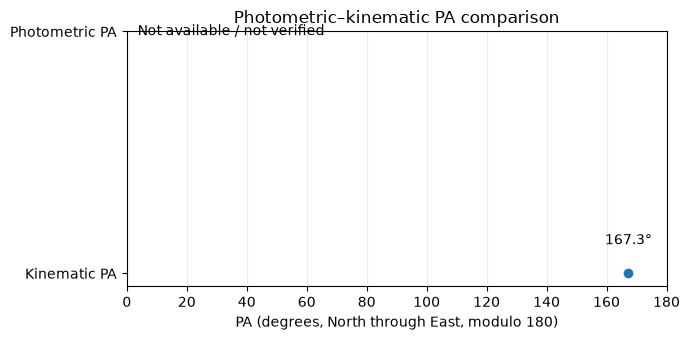

In [21]:

summary = {
 "plateifu": f"{PLATE}-{IFU}",
 "mangaid": primary.get("MANGAID","not recorded"),
 "daptype": primary.get("DAPTYPE","not recorded"),
 "kinematic_pa_deg_N_through_E": KIN_PA_DEG,
 "photometric_pa_raw_deg": phi_raw,
 "photometric_pa_converted_deg": PHOT_PA_NORTH_THROUGH_EAST_DEG
       if PHOT_PA_NORTH_THROUGH_EAST_DEG is not None else np.nan,
 "photometric_pa_source_and_convention": PA_CONVENTION_SOURCE or "not verified",
 "axis_ratio_b_over_a": ba,
 "ellipticity_1_minus_b_over_a": ellipticity,
 "NSA_half_light_radius_arcsec": re_arcsec,
 "DAP_implied_Re_arcsec": re_dap,
 "Sersic_n": sersic_n,
 "PA_misalignment_deg": pa_delta_180(KIN_PA_DEG,PHOT_PA_NORTH_THROUGH_EAST_DEG)
       if PHOT_PA_NORTH_THROUGH_EAST_DEG is not None else np.nan
}
summary_df = pd.DataFrame([summary])
display(summary_df.T)
summary_df.to_csv(REP/"milestone11_photometric_geometry_summary.csv",index=False)

fig,ax=plt.subplots(figsize=(7,3.5))
for y,(label,val) in enumerate([
 ("Kinematic PA",KIN_PA_DEG),
 ("Photometric PA",PHOT_PA_NORTH_THROUGH_EAST_DEG)]):
    ax.set_yticks([0,1],["Kinematic PA","Photometric PA"])
    if val is not None and np.isfinite(val):
        ax.plot(val,y,"o"); ax.text(val,y+0.12,f"{val:.1f}°",ha="center")
    else:
        ax.text(0.02,y,"Not available / not verified",transform=ax.get_yaxis_transform(),va="center")
ax.set_xlim(0,180); ax.set_xlabel("PA (degrees, North through East, modulo 180)")
ax.set_title("Photometric–kinematic PA comparison"); ax.grid(axis="x",alpha=.25)
fig.tight_layout(); fig.savefig(FIG/"milestone11_pa_comparison.png",dpi=180); plt.show()


## 5. Scientific interpretation checklist

- [ ] Target is uniquely matched in DRPall.
- [ ] Exact DRPall/NSA release is recorded.
- [ ] Photometric PA convention is verified and converted.
- [ ] Axis ratio and ellipticity definitions are stated.
- [ ] NSA half-light radius is compared with DAP radial scaling.
- [ ] Photometric and DAP centres are checked before geometric interpretation.
- [ ] Inclination estimates account for intrinsic galaxy thickness.
- [ ] PA misalignment is not treated as evidence of an SMBH binary by itself.

### Expected outputs
- `outputs/reports/milestone11_photometric_geometry_summary.csv`
- `outputs/figures/milestone11_pa_comparison.png`

If DRPall is absent, the notebook will still inspect MAPS metadata and DAP radial scaling, but photometric geometry remains incomplete until sourced catalogue/imaging data are added.
